<a href="https://colab.research.google.com/github/juliaR0/SF_10_new/blob/main/notebooks/Prototype_1.2_112326.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bilingual agrammatism prototype 1(Nov 20–23, 2026)

*Code in this notebook was assisted with Claude (Anthropic) and run, debugged and adapted by me. Prompts are in my AI log. Text cells marked "Summarized with Claude AI" were drafted by Claude.*

**This is a compilation of different notebooks**, find originals on github repo.

**Process record:** failed attempts are summarized in the Appendix; the original working notebooks are in the GitHub history.

**How to use:** Runtime → Run all. Every model run checks whether its results folder already exists and skips itself if it does, so re-running is fast. To redo a run, delete its folder in `simulations/` first.

**Contents**
1. Setup + helper functions (run first, always)
2. Chunk 0 — Baseline reproduction
3. Chunk 1a — Toy-language check
4. Chunk 3 prep — Inside the weight files
5. Chunk 3a — Pilot lesion
6. Chunk 5a — Pilot therapy
7. Chunk 2 — Healthy twins with a language history
8. Chunk 5b — Connect everything (late learner → damage → therapy) *(not run yet)*
9. Appendix — Dead ends (what didn't work and why)

## About this prototype

This notebook is an ugly, end-to-end prototype: train bilingual "twins," damage their grammar pathway, then simulate therapy. It tests whether the pipeline works, not final results (1–2 twins, few seeds, small test sets).

**Model:** the Bilingual Dual-path model (Tsoukala et al., 2019; code: github.com/xtsoukala/dual_path), run unchanged with its toy English–Spanish language. It builds on Chang's Dual-path model (Chang, 2002; Chang, Dell & Bock, 2006).

**Method ideas borrowed:** damaging a trained network to simulate brain damage, and retraining it as therapy (Hinton & Shallice, 1991; Plaut, 1996); simulated bilingual aphasia therapy (BiLex: Kiran, Grasemann et al., 2021); complexity-based therapy and argument structure (Thompson et al., 2003; 2013).

**Mine:** the lesion sites and control, the therapy and sham conditions, the language-history twins, and the analysis.

Tsoukala, C., Frank, S. L., van den Bosch, A., Valdés Kroff, J., & Broersma, M. (2019). Simulating Spanish-English code-switching: El modelo está generating code-switches. *CMCL Workshop*, 20–29. https://aclanthology.org/W19-2903

## 1. Setup

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
# FIX: only clone the repo if it isn't already in Drive
if not os.path.exists('/content/drive/MyDrive/dual_path'):
    !git clone https://github.com/xtsoukala/dual_path.git /content/drive/MyDrive/dual_path
%cd /content/drive/MyDrive/dual_path

Mounted at /content/drive
/content/drive/MyDrive/dual_path


In [3]:
# FIX: requirements.txt pins old versions that fail on Colab's Python 3.13 -> remove "==version"
!sed 's/==.*//' requirements.txt > requirements_unpinned.txt
!pip install -q -r requirements_unpinned.txt

## Helper functions
Defined once here so every later cell can use them.

In [4]:
import sys, os, copy, json, glob, pickle, shutil, lz4.frame, torch
import pandas as pd
sys.path.insert(0, 'src')          # so pickle can rebuild the repo's layer objects
pd.set_option('display.max_rows', 200, 'display.max_colwidth', 100)

def dp(args, resdir):
    """Run the model with these options, unless simulations/<resdir> already exists."""
    if os.path.exists(f'simulations/{resdir}'):
        print('skip (already exists):', resdir)
        return
    cmd = f'python src/start_dual_path.py {args} --resdir {resdir}'
    print(cmd)
    get_ipython().system(cmd)

def lang_of(msg):
    """Target language of a test sentence, from its message."""
    return 'es' if 'TARGET-LANG=es' in str(msg) else 'en'

def structure(msg):
    """Sentence type from its message: how many participants the verb has."""
    msg = str(msg)
    if 'RECIPIENT=' in msg: return '3 ditransitive'
    if 'PATIENT=' in msg:   return '2 transitive'
    if 'ATTR=' in msg:      return 'copular'
    return '1 intransitive'

def load_test(path, epoch=None):
    """Read a test.csv and turn the text 'True'/'False' columns into real True/False."""
    d = pd.read_csv(path)
    if epoch is not None:
        d = d[d.epoch == epoch].copy()
    d['m'] = d['meaning'].astype(str).str.strip()        # 'True' / 'False' / 'flex-False'
    for col in ['is_grammatical', 'is_code_switched']:
        d[col] = d[col].astype(str).str.strip() == 'True'
    d['tlang'] = d.message.apply(lang_of)
    d['struct'] = d.message.apply(structure)
    return d

def pct(mask):
    return round(100 * mask.mean(), 1)

def load_weights(path):
    with lz4.frame.open(path, 'rb') as f:
        return pickle.load(f)

def lesion(layers, layer_name, fraction, seed=0, rows=slice(None)):
    """Damaged COPY of layers: zero a random `fraction` of layer_name's incoming weights (only `rows`)."""
    damaged = copy.deepcopy(layers)                   # never touch the healthy weights
    W = damaged[layer_name].in_weights
    g = torch.Generator().manual_seed(seed)           # same seed = same damage
    mask = torch.rand(W[rows].shape, generator=g) < fraction
    W[rows] = W[rows].masked_fill(mask, 0.0)
    return damaged

def save_layers(layers, folder, epoch, sim=1):
    """Save in BOTH places the repo looks: folder/<sim>/weights and folder/weights (startup quirk)."""
    for path in [f'{folder}/{sim}/weights', f'{folder}/weights']:
        os.makedirs(path, exist_ok=True)
        with lz4.frame.open(f'{path}/w{epoch}.lz4', 'wb') as f:
            pickle.dump(layers, f, protocol=-1)

def build_input(folder, src_run, sentence_filter=None, max_n=None, sim=1):
    """Input folder for --input: folder/input (shared files) + folder/<sim> (training.in, test.in).
    sentence_filter keeps only some training lines (e.g. therapy sentences)."""
    os.makedirs(f'{folder}/input', exist_ok=True); os.makedirs(f'{folder}/{sim}', exist_ok=True)
    for f in os.listdir(f'{src_run}/input'):
        p = f'{src_run}/input/{f}'
        if os.path.isfile(p): shutil.copyfile(p, f'{folder}/input/{f}')
    lines = open(f'{src_run}/{sim}/training.in').read().splitlines()
    if sentence_filter: lines = [l for l in lines if sentence_filter(l)]
    if max_n: lines = lines[:max_n]
    open(f'{folder}/{sim}/training.in', 'w').write('\n'.join(lines) + '\n')
    shutil.copyfile(f'{src_run}/{sim}/test.in', f'{folder}/{sim}/test.in')
    print(folder, len(lines), 'training sentences')
    return folder

## 2. Chunk 0 — Baseline reproduction

*Summarized with Claude AI*

**Goal:** Run the Bilingual Dual-path model (Tsoukala et al.) with no changes and check that it matches the published results.

**What I ran:** 4 simulated speakers ("twins"), 20 epochs, Spanish + English, both languages active at test (`--cs`).

**Results (epoch 20):**
- Mean code-switching: **19.3%** (paper: 18.09%) → **reproduced**
- Meaning accuracy: 87.4%, 91.0%, 73.8%, 78.6% (twin 3 is below my 75% cutoff)
- Grammar reached ~95% by epoch 2; meaning leveled off around 83% by epoch 9

**Notes:**
- The repo's meaning score counts article/tense-only mistakes (flex-False) as correct (87.4% = (430 + 7)/500). For agrammatism I use the strict score.
- The weaker language did not reliably make more errors or switch more (clear in 1 of 4 twins).

In [ ]:
# FIX: the README command is terminal code, so it needs "!" in Colab (dp() does this)
dp('--sim 4 --epochs 20 --cs --lang es en', 'results')

skip (already exists): results


{
  "hidden": 80,
  "compress": null,
  "epochs": 20,
  "l2_epoch": null,
  "l2_decimal_fraction": 0.5,
  "input": null,
  "resdir": "results",
  "lexicon": "./data/code-switching/lexicon.csv",
  "structures": "./data/code-switching/structures.csv",
  "trainingset": "training.in",
  "testset": "test.in",
  "primingset": null,
  "languages": [
    "es",
    "en"
  ],
  "target_lang": [
    "es",
    "en"
  ],
  "lrate": 0.1,
  "final_lrate": 0.02,
  "momentum": 0.9,
  "set_weights": null,
  "set_weights_epoch": null,
  "fw": 15,
  "fwi": 10,
  "cognate_decimal_fraction": 0.3,
  "exclude_cognates": null,
  "cognate_list": null,
  "false_friends_lexicon": null,
  "concepts_to_evaluate": null,
  "messageless_decimal_fraction": 0,
  "generate_training_num": 2000,
  "generate_test_num": 600,
  "training_files_path": null,
  "title": null,
  "sim": 4,
  "sim_from": null,
  "sim_to": null,
  "threshold": 0,
  "config_file": false,
  "generator_timeout": 120,
  "hidden_dev": 10,
  "compress_dev

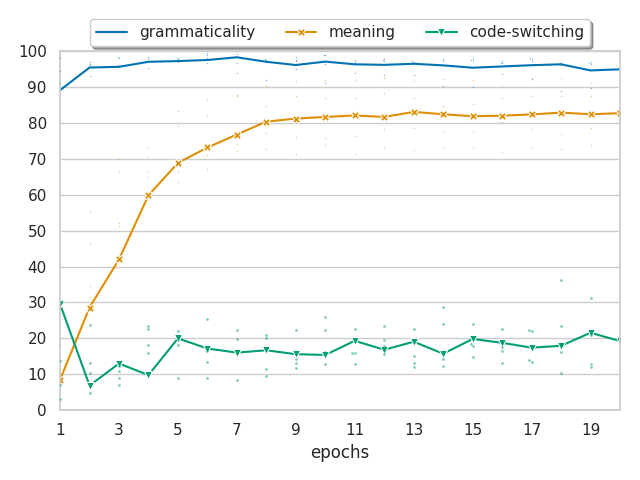

In [ ]:
!cat simulations/results/commandline_args.txt
from IPython.display import Image, display
for p in sorted(glob.glob('simulations/results/*.png')):
    display(Image(p, width=600))

In [ ]:
# Twin 1's mistakes at epoch 20
t20 = load_test('simulations/results/1/test.csv', epoch=20)
print(len(t20), 'sentences;', (t20.m != 'True').sum(), 'wrong')
print(t20.m.value_counts())
t20[t20.m != 'True'][['m', 'target_sentence', 'produced_sentence']].head(15)

500 sentences; 70 wrong
m
True          430
False          63
flex-False      7
Name: count, dtype: int64


,m,target_sentence,produced_sentence
10004,flex-False,the waitress shows the brother a key .,the waitress shows a brother a key .
10011,False,la abuela amable ha llegado .,la abuela feliz has arrived .
10019,False,la camarera pateó la llave .,la camarera empujó the key .
10022,False,a sad waitress throws the book to a aunt .,a sad throws throws the book to a aunt .
10032,False,the short boy pushes the key .,the short boy has the key .
10033,False,la tía está inteligente .,la tía está atenta .
10035,False,el camarero tranquilo llegó .,el camarero arrived .
10037,False,el hermano feliz ha estornudado .,el hermano sneezed has sneezed .
10039,False,él está pequeño .,él está feliz .
10042,False,el camarero empuja una silla .,el camarero pushed a chair .


In [ ]:
# All 4 twins by language at epoch 20
rows = []
for sim in [1, 2, 3, 4]:
    d = load_test(f'simulations/results/{sim}/test.csv', epoch=20)
    for lg, g in d.groupby('tlang'):
        rows.append({'twin': sim, 'lang': lg, 'n': len(g), 'meaning_%': pct(g.m == 'True'),
                     'switch_%': pct(g.is_code_switched), 'flex_errors': (g.m == 'flex-False').sum()})
pd.DataFrame(rows)

,twin,lang,n,meaning_%,switch_%,flex_errors
0,1,en,315,94.6,2.2,7
1,1,es,185,71.4,60.5,0
2,2,en,235,91.9,7.2,2
3,2,es,265,89.4,19.2,0
4,3,en,320,75.3,18.4,3
5,3,es,180,69.4,15.0,0
6,4,en,250,75.2,57.6,0
7,4,es,250,82.0,17.6,0


## 3. Chunk 1a — Toy-language check

*Summarized with Claude AI*

**Sentence patterns (`structures.csv`, 33):** intransitive (*the brother sneezes*), transitive (*the waiter pushes the key*), ditransitive (*the aunt gives the book to the boy*, ~10%), copular, possession. Tenses: present, past, progressive, perfect. **Missing:** passives, questions, relative clauses, plurals, negation, object pronouns.
→ Classic CATE can't be tested, but there's an **argument-structure ladder** (1 → 2 → 3 participants) → **Option A**.

**Words (`lexicon.csv`, 111):** 26 nouns, adjectives, subject pronouns; verbs: 8 intransitive, 3 transitive, 3 ditransitive (too few to hold some out).

**Bugs found:** no "an" (*a aunt*); *throwed*; Spanish copular only *está*.

**Scoring:** flex-False = wrong only because of articles or auxiliaries. Article check works in both languages (the 0 Spanish article errors are real). ⚠️ Tense check only looks at auxiliaries → verb-form errors (*pushes → pushed*) are not counted → I need my own tense scorer.

In [ ]:
s = pd.read_csv('data/code-switching/structures.csv')
print(s.shape); s

(33, 5)


,message,es,percentage_es,en,percentage_en
0,"AGENT=;AGENT-MOD=;ACTION-LINKING=;EVENT-SEM=PRESENT,PROGRESSIVE,AGENT,AGENT-MOD,ACTION-LINKING",det noun:animate adj:animate aux::present:progressive:singular participle:intrans::progressive,2.00,det adj:animate noun:animate aux::present:progressive:singular participle:intrans::progressive,2.00
1,"AGENT=;ACTION-LINKING=;EVENT-SEM=PRESENT,PROGRESSIVE,AGENT,ACTION-LINKING",det noun:animate aux::present:progressive:singular participle:intrans::progressive,4.00,det noun:animate aux::present:progressive:singular participle:intrans::progressive,4.00
2,"AGENT=pron;ACTION-LINKING=;EVENT-SEM=PRESENT,PROGRESSIVE,AGENT,ACTION-LINKING",pron aux::present:progressive:singular participle:intrans::progressive,3.50,pron aux::present:progressive:singular participle:intrans::progressive,3.50
3,"AGENT=;ACTION-LINKING=;PATIENT=;EVENT-SEM=PRESENT,PROGRESSIVE,AGENT,ACTION-LINKING,PATIENT",det noun:animate aux::present:progressive:singular participle:trans::progressive det noun:inanimate,4.00,det noun:animate aux::present:progressive:singular participle:trans::progressive det noun:inanimate,4.00
4,"AGENT=pron;ACTION-LINKING=;PATIENT=;EVENT-SEM=PRESENT,PROGRESSIVE,AGENT,ACTION-LINKING,PATIENT",pron aux::present:progressive:singular participle:trans::progressive det noun:inanimate,3.50,pron aux::present:progressive:singular participle:trans::progressive det noun:inanimate,3.50
5,"AGENT=;AGENT-MOD=;ACTION-LINKING=;PATIENT=;EVENT-SEM=PRESENT,PROGRESSIVE,AGENT,AGENT-MOD,ACTION-...",det noun:animate adj:animate aux::present:progressive:singular participle:trans::progressive det...,2.00,det adj:animate noun:animate aux::present:progressive:singular participle:trans::progressive det...,2.00
6,"AGENT=;AGENT-MOD=;ACTION-LINKING=;EVENT-SEM=PRESENT,PERFECT,AGENT,AGENT-MOD,ACTION-LINKING",det noun:animate adj:animate aux::present:perfect:singular participle:intrans::perfect,2.00,det adj:animate noun:animate aux::present:perfect:singular participle:intrans::perfect,2.00
7,"AGENT=;ACTION-LINKING=;EVENT-SEM=PRESENT,PERFECT,AGENT,ACTION-LINKING",det noun:animate aux::present:perfect:singular participle:intrans::perfect,4.00,det noun:animate aux::present:perfect:singular participle:intrans::perfect,4.00
8,"AGENT=pron;ACTION-LINKING=;EVENT-SEM=PRESENT,PERFECT,AGENT,ACTION-LINKING",pron aux::present:perfect:singular participle:intrans::perfect,3.50,pron aux::present:perfect:singular participle:intrans::perfect,3.50
9,"AGENT=;AGENT-MOD=;ACTION-LINKING=;PATIENT=;EVENT-SEM=PRESENT,PERFECT,AGENT,AGENT-MOD,ACTION-LINK...",det noun:animate adj:animate aux::present:perfect:singular participle:trans::perfect det noun:in...,2.00,det adj:animate noun:animate aux::present:perfect:singular participle:trans::perfect det noun:in...,2.00


In [ ]:
lex = pd.read_csv('data/code-switching/lexicon.csv')
print(lex.shape); print(lex.pos.value_counts())
lex[lex.pos.isin(['verb', 'aux', 'participle', 'prep'])][['morpheme_es', 'morpheme_en', 'concept', 'pos', 'type', 'tense', 'aspect']]

(111, 18)
pos
verb          31
participle    28
noun          26
adj           16
det            4
aux            2
pron           2
.              1
prep           1
Name: count, dtype: int64


,morpheme_es,morpheme_en,concept,pos,type,tense,aspect
49,está,is,BE,verb,copular,present,NaN
50,tiene,has,HAS,verb,possession,present,NaN
51,está,is,NaN,aux,auxiliary_verb,present,progressive
52,ha,has,NaN,aux,auxiliary_verb,present,perfect
53,tenía,had,HAS,verb,possession,past,NaN
54,nada,swims,SWIM,verb,intrans,present,NaN
55,salta,jumps,JUMP,verb,intrans,present,NaN
56,camina,walks,WALK,verb,intrans,present,NaN
57,corre,runs,RUN,verb,intrans,present,NaN
58,llega,arrives,ARRIVE,verb,intrans,present,NaN


In [ ]:
# Article-only mistakes, all twins, all epochs
def only_article_diff(row, arts):
    tgt, prod = str(row.target_sentence).split(), str(row.produced_sentence).split()
    if len(tgt) != len(prod): return False
    diffs = [(a, b) for a, b in zip(tgt, prod) if a != b]
    return len(diffs) > 0 and all(a in arts and b in arts for a, b in diffs)

rows = []
for sim in [1, 2, 3, 4]:
    d = pd.read_csv(f'simulations/results/{sim}/test.csv')
    d['meaning'] = d['meaning'].astype(str).str.strip()
    for lg, arts in [('es', {'el', 'la', 'un', 'una'}), ('en', {'the', 'a'})]:
        hits = d[d.apply(only_article_diff, axis=1, arts=arts)]
        for label, n in hits.meaning.value_counts().items():
            rows.append({'twin': sim, 'lang': lg, 'label': label, 'count': n})
pd.DataFrame(rows).pivot_table(index='lang', columns='label', values='count', aggfunc='sum', fill_value=0)

label,flex-False
lang,
en,170


In [ ]:
# How the scoring decides flex-False
!grep -n "def test_without_feature" -A 10 src/modules/formatter.py
!grep -n "self.determiners =\|self.tense_markers =" -A 3 src/modules/formatter.py

432:    def test_without_feature(self, out_sentence_idx, trg_sentence_idx, feature):
433-        if feature == "tense":
434-            feature_markers = self.tense_markers
435-        elif feature == "determiners":
436-            feature_markers = self.determiners
437-        return self.test_for_flexible_order(
438-            filter(lambda i: i not in feature_markers, out_sentence_idx),
439-            filter(lambda i: i not in feature_markers, trg_sentence_idx),
440-            ignore_det=False,
441-        )
442-
170:        self.determiners = self.df_query_to_idx("pos == 'det'")
171:        self.tense_markers = self.df_query_to_idx(
172-            "pos == 'aux' or pos == 'verb_suffix'"
173-        )
174-        self.cognate_idx = self.df_query_to_idx("is_cognate == True", lang=self.L[1])


## 4. Chunk 3 prep — Inside the weight files

*Summarized with Claude AI*

Each `weights/w{epoch}.lz4` = all 13 layers (pickle + lz4). Each layer keeps its incoming weights in `in_weights` [inputs × units], in the order of `in_layer_names`. No biases.

- Grammar path: input → compress → hidden → **pred_compress** → output (output rows 55–110)
- Meaning path: concept/identifiability → role (message weights) → hidden → **pred_role** → pred_concept/pred_identifiability (message weights) → output (rows 0–54)
- Sentence files: `sentence ## message`, one per line.

In [ ]:
w = load_weights('simulations/results/1/weights/w20.lz4')     # twin 1, fully trained
for name, L in w.items():
    print(f'{name:22s} size {L.size:4d} | weights {tuple(L.in_weights.shape)} | fed by {L.in_layer_names}')

input                  size  202 | weights (0, 202) | fed by ()
identifiability        size    3 | weights (202, 3) | fed by ('input',)
concept                size   52 | weights (202, 52) | fed by ('input',)
role                   size    6 | weights (55, 6) | fed by ('identifiability', 'concept')
compress               size   56 | weights (202, 56) | fed by ('input',)
eventsem               size   12 | weights (0, 12) | fed by ()
target_lang            size    2 | weights (0, 2) | fed by ()
hidden                 size   74 | weights (150, 74) | fed by ('role', 'eventsem', 'target_lang', 'compress')
pred_role              size    6 | weights (74, 6) | fed by ('hidden',)
pred_identifiability   size    3 | weights (6, 3) | fed by ('pred_role',)
pred_concept           size   52 | weights (6, 52) | fed by ('pred_role',)
pred_compress          size   56 | weights (74, 56) | fed by ('hidden',)
output                 size  202 | weights (111, 202) | fed by ('pred_identifiability', 'pred_conc

## 5. Chunk 3a — Pilot lesion

*Summarized with Claude AI*

**Method:** damage twin 1's healthy `w20` (zero a random fraction of one weight table, seeded), save, then test with no learning: `--sw <folder> --swe 20 --epochs 1 --input simulations/results --norandomization --hidden 74 --compress 56 --fw 19`, **epoch 0 rows only** (tested before the 1 epoch of training). Sanity check: the 0% copy scored 85.8% meaning (healthy 86.0%).

**Sites:** grammar_A = hidden → pred_compress · control_meaning = hidden → pred_role

| Meaning % | Intrans. | Trans. | Ditrans. | Grammatical % |
|---|---|---|---|---|
| Healthy | 83 | 90 | 77 | 97 |
| Grammar 40–50% (4 of 5 seeds) | ~80 | ~85 | **21–48** | 85–97 |
| Meaning 40–50% | **26–29** | 47–49 | 50 | 91 |
| Grammar 60–95% | collapse | collapse | collapse | 14–63 |

**Findings:** grammar damage hits **3-participant sentences first** (dropped recipients); meaning damage gives the **opposite shape** → start of a double dissociation. Heavy damage = general collapse. flex-False did not rise.

**Limits:** 1 twin, few seeds, ~50 ditransitive test items, no statistics.

In [ ]:
TWIN1 = '--norandomization --sim 1 --epochs 1 --hidden 74 --compress 56 --fw 19 --cs --lang es en --input simulations/results'
SITES = {'grammar_A': 'pred_compress', 'control_meaning': 'pred_role'}

def run_lesion(site, fraction, seed=0, folder=None, resdir=None):
    tag = f"{site}_{int(fraction*100):02d}_s{seed}"
    folder = folder or f'simulations/lesion_{tag}'
    resdir = resdir or f'eval_{tag}'
    if not os.path.exists(f'{folder}/weights/w20.lz4'):
        save_layers(lesion(w, SITES[site], fraction, seed), folder, epoch=20)
    dp(f'{TWIN1} --sw {folder} --swe 20', resdir)
    return f'simulations/{resdir}/1/test.csv'

# sanity check (0%) and the first 40% lesion, under their original folder names
p00 = run_lesion('grammar_A', 0.0, folder='simulations/lesion_grammarA_00', resdir='eval_grammarA_00_v7')
p40 = run_lesion('grammar_A', 0.4, folder='simulations/lesion_grammarA_40', resdir='eval_grammarA_40_v1')
print('0% meaning:', pct(load_test(p00, epoch=0).m == 'True'), '(healthy 86.0)')

skip (already exists): eval_grammarA_00_v7
skip (already exists): eval_grammarA_40_v1
0% meaning: 85.8 (healthy 86.0)


In [ ]:
# Severity sweep + more seeds + the meaning control
runs = {('grammar_A', 0.0, 0): p00, ('grammar_A', 0.4, 0): p40}
for frac in [0.6, 0.8, 0.95]:
    runs[('grammar_A', frac, 0)] = run_lesion('grammar_A', frac)
for seed in [1, 2]:
    for frac in [0.4, 0.5]:
        runs[('grammar_A', frac, seed)] = run_lesion('grammar_A', frac, seed)
for frac in [0.4, 0.5]:
    runs[('control_meaning', frac, 0)] = run_lesion('control_meaning', frac)

rows = []
for (site, frac, seed), path in runs.items():
    d = load_test(path, epoch=0)
    r = {'site': site, 'damage': frac, 'seed': seed}
    for s_, g in d.groupby('struct'):
        r[s_] = pct(g.m == 'True')
    r['grammatical_%'] = pct(d.is_grammatical)
    r['flex_False'] = (d.m == 'flex-False').sum()
    rows.append(r)
pd.DataFrame(rows)

skip (already exists): eval_grammar_A_60_s0
skip (already exists): eval_grammar_A_80_s0
skip (already exists): eval_grammar_A_95_s0
skip (already exists): eval_grammar_A_40_s1
skip (already exists): eval_grammar_A_50_s1
skip (already exists): eval_grammar_A_40_s2
skip (already exists): eval_grammar_A_50_s2
skip (already exists): eval_control_meaning_40_s0
skip (already exists): eval_control_meaning_50_s0


,site,damage,seed,1 intransitive,2 transitive,3 ditransitive,copular,grammatical_%,flex_False
0,grammar_A,0.00,0,83.1,90.0,76.9,87.0,97.0,7
1,grammar_A,0.40,0,89.6,90.0,25.0,97.8,96.6,5
2,grammar_A,0.60,0,29.5,11.4,3.8,50.0,27.4,1
3,grammar_A,0.80,0,35.0,37.4,13.5,76.1,62.8,7
4,grammar_A,0.95,0,1.6,0.0,0.0,23.9,13.8,0
5,grammar_A,0.40,1,78.7,86.3,75.0,82.6,94.0,6
6,grammar_A,0.50,1,76.0,80.4,44.2,78.3,85.2,1
7,grammar_A,0.40,2,83.1,82.2,21.2,82.6,92.2,4
8,grammar_A,0.50,2,82.0,90.4,48.1,100.0,94.4,0
9,control_meaning,0.40,0,29.0,48.9,50.0,80.4,91.2,1


In [ ]:
# Read the 40% lesion's mistakes
dmg = load_test(p40, epoch=0)
dmg[dmg.m != 'True'][['m', 'target_sentence', 'produced_sentence']].head(20)

,m,target_sentence,produced_sentence
18,flex-False,a gentleman shows a book to the waitress .,a gentleman shows the book to the waitress .
22,False,a sad waitress throws the book to a aunt .,a sad throws throws the book to a aunt .
32,False,the short boy pushes the key .,the short boy has the key .
43,False,he throws a toy to the waitress .,he throws a toy .
66,False,the aunt ran .,the aunt ate .
68,False,un tío pequeño tira a_ un tío una pelota .,a short uncle throws a ball .
71,False,ella muestra a_ una niña el juguete .,ella muestra shows toy .
79,False,él ha pateado un bolígrafo .,he has kicked a toy .
92,False,she shows a sister a book .,she shows shows book .
98,False,un padre tira a_ el abuelo un juguete .,a father throws a grandfather the grandfather .


## 6. Chunk 5a — Pilot therapy

*Summarized with Claude AI*

**Method:** patient = twin 1, grammar_A 40%, seed 0 (ditransitives 77 → 25). Therapy = only ditransitive training sentences in one language (English 131, Spanish 77), 5 sessions (epochs), learning rate fixed at 0.02 (`--lrate 0.02 --nodlr`). Sham control = 131 English intransitive sentences. Same 500 test sentences.

| Ditransitive meaning % | English | Spanish |
|---|---|---|
| Ditransitive therapy, English | 29 → 79 | 17 → 78 |
| Ditransitive therapy, Spanish | 29 → 71 | 11 → 67 |
| Sham (English intransitive) | 29 → 35 | 11 → 0 |

**Findings:** therapy restored the trained structure and **transferred across languages** both ways; sham did not; all 52 test ditransitives are unseen (no sentence or meaning overlap with therapy) → generalization, not memorization. English therapy slightly lowered English simple structures (forgetting). CATE (complex → simple) not testable at 40%.

**Limits:** 34 English / 18 Spanish ditransitive test items, 1 twin, 1 seed, unequal therapy sizes, epoch-0 scores vary slightly between runs, 100/500 test sentences also in original training.

In [ ]:
THERAPY1 = '--norandomization --sim 1 --epochs 5 --lrate 0.02 --nodlr --hidden 74 --compress 56 --fw 19 --cs --lang es en --sw simulations/lesion_grammarA_40 --swe 20'

for lg in ['en', 'es']:
    f = build_input(f'simulations/therapy_ditrans_{lg}', 'simulations/results',
                    lambda l, lg=lg: 'RECIPIENT=' in l and f'TARGET-LANG={lg}' in l)
    dp(f'{THERAPY1} --input {f}', f'therapy_{lg}_v3')

f = build_input('simulations/therapy_intrans_en', 'simulations/results',
                lambda l: structure(l.split('##')[-1]) == '1 intransitive' and 'TARGET-LANG=en' in l, max_n=131)
dp(f'{THERAPY1} --input {f}', 'therapy_sham_en_v1')

simulations/therapy_ditrans_en 131 training sentences
skip (already exists): therapy_en_v3
simulations/therapy_ditrans_es 77 training sentences
skip (already exists): therapy_es_v3
simulations/therapy_intrans_en 131 training sentences
skip (already exists): therapy_sham_en_v1


In [ ]:
rows = []
for name, resdir in [('ditrans EN', 'therapy_en_v3'), ('ditrans ES', 'therapy_es_v3'), ('sham EN', 'therapy_sham_en_v1')]:
    d = load_test(f'simulations/{resdir}/1/test.csv')
    for (ep, s_, tl), g in d.groupby(['epoch', 'struct', 'tlang']):
        rows.append({'therapy': name, 'structure': s_, 'test_lang': tl, 'epoch': ep, 'meaning_%': pct(g.m == 'True')})
pd.DataFrame(rows).pivot_table(index=['therapy', 'structure', 'test_lang'], columns='epoch', values='meaning_%')

epoch                                    0      1      2      3      4      5
therapy    structure      test_lang                                          
ditrans EN 1 intransitive en          94.8   93.0   93.0   91.3   91.3   90.4
                          es          63.2   72.1   67.6   67.6   67.6   69.1
           2 transitive   en          95.6   93.4   91.2   90.4   86.8   83.8
                          es          66.3   75.9   75.9   77.1   75.9   75.9
           3 ditransitive en          29.4   76.5   82.4   85.3   79.4   79.4
                          es          16.7   66.7   61.1   55.6   61.1   77.8
           copular        en         100.0  100.0  100.0  100.0  100.0   93.3
                          es          75.0   81.2   75.0   68.8   68.8   62.5
ditrans ES 1 intransitive en          94.8   95.7   95.7   96.5   96.5   95.7
                          es          63.2   70.6   70.6   67.6   69.1   69.1
           2 transitive   en          95.6   91.9   91.2   91.9   91.2   89.7
                          es          66.3   66.3   69.9   72.3   72.3   75.9
           3 ditransitive en          29.4   38.2   52.9   67.6   52.9   70.6
                          es          11.1   55.6   66.7   66.7   72.2   66.7
           copular        en         100.0  100.0  100.0  100.0  100.0  100.0
                          es          75.0   62.5   62.5   68.8   68.8   68.8
sham EN    1 intransitive en          94.8   96.5   97.4   96.5   96.5   96.5
                          es          80.9   92.6   94.1   94.1   95.6   95.6
           2 transitive   en          95.6   94.1   93.4   93.4   91.9   93.4
                          es          66.3   80.7   81.9   81.9   79.5   80.7
           3 ditransitive en          29.4   32.4   32.4   29.4   38.2   35.3
                          es          11.1    0.0    0.0    0.0    0.0    0.0
           copular        en         100.0  100.0  100.0  100.0  100.0  100.0
                          es          75.0   81.2   81.2   81.2   81.2   81.2

In [ ]:
# Overlap checks
tr = set(l.split('##')[0].strip() for l in open('simulations/results/1/training.in'))
te = [l.split('##')[0].strip() for l in open('simulations/results/1/test.in')]
print(sum(s_ in tr for s_ in te), 'of', len(te), 'test sentences also in original training')

def strip_lang(msg):
    return ';'.join(p for p in str(msg).split(';') if not p.startswith('TARGET-LANG'))

for lg in ['en', 'es']:
    th = open(f'simulations/therapy_ditrans_{lg}/1/training.in').read().splitlines()
    th_sent = set(l.split('##')[0].strip() for l in th)
    th_msg = set(strip_lang(l.split('##')[1]) for l in th)
    d = load_test(f'simulations/therapy_{lg}_v3/1/test.csv')
    d = d[d.struct == '3 ditransitive'].copy()
    d['seen'] = d.target_sentence.str.strip().isin(th_sent) | d.message.apply(strip_lang).isin(th_msg)
    print(f'\n{lg} therapy:')
    print(d[d.epoch.isin([0, 5])].groupby(['tlang', 'seen', 'epoch'])
          .apply(lambda g: f"{pct(g.m == 'True'):.0f}% (n={len(g)})", include_groups=False).unstack())

100 of 500 test sentences also in original training

en therapy:
epoch                 0           5
tlang seen                         
en    False  29% (n=34)  79% (n=34)
es    False  17% (n=18)  78% (n=18)

es therapy:
epoch                 0           5
tlang seen                         
en    False  29% (n=34)  71% (n=34)
es    False  11% (n=18)  67% (n=18)


## 7. Chunk 2 — Healthy twins with a language history

*Summarized with Claude AI*

**Profiles** (prototype stand-ins for real LEX-BADAT profiles; 2 twins each, `--norandomization`):
- **Balanced early:** 50/50 from epoch 0, 20 epochs
- **Late learner:** Spanish only for 10 epochs, then load epoch 10 (`--sw … --swe 10`) and train 10 more at 50/50

| Meaning % | Twin | English | Spanish |
|---|---|---|---|
| Balanced | 1 | 94 | 82 |
| Balanced | 2 | 91 | 84 |
| Late | 1 | 70 | 93 |
| Late | 2 | 51 | 93 |

**Findings:** late learners are **Spanish-dominant**, as designed → language history works as a knob. Balanced exposure did **not** give balanced ability (English easier in this toy language). Twins with identical settings differ a lot in switching (65% vs 21%). Late learners' English may be under-trained.

**Next:** real LEX-BADAT profiles; how ages map to epochs; try the repo's `--l2-epoch` route.

In [ ]:
dp('--sim 2 --epochs 20 --cs --lang es en --norandomization --l2-decimal-fraction 0.5', 'twins_balanced_v1')

# Late learner, step 1: Spanish only
dp('--sim 2 --epochs 10 --cs --lang es en --norandomization --l2-decimal-fraction 0', 'late_step1_v1')
# startup quirk: the repo also looks for weights in folder/weights
os.makedirs('simulations/late_step1_v1/weights', exist_ok=True)
shutil.copyfile('simulations/late_step1_v1/1/weights/w10.lz4', 'simulations/late_step1_v1/weights/w10.lz4')
# step 2: load epoch 10, add English
dp('--sim 2 --epochs 10 --cs --lang es en --norandomization --l2-decimal-fraction 0.5 --sw simulations/late_step1_v1 --swe 10', 'twins_late_v1')

skip (already exists): twins_balanced_v1
skip (already exists): late_step1_v1
skip (already exists): twins_late_v1


In [ ]:
rows = []
for profile, folder, ep in [('balanced', 'twins_balanced_v1', 20), ('late', 'twins_late_v1', 10)]:
    for sim in [1, 2]:
        d = load_test(f'simulations/{folder}/{sim}/test.csv', epoch=ep)
        for tl, g in d.groupby('tlang'):
            rows.append({'profile': profile, 'twin': sim, 'test_lang': tl, 'n': len(g),
                         'meaning_%': pct(g.m == 'True'), 'switch_%': pct(g.is_code_switched)})
pd.DataFrame(rows)

,profile,twin,test_lang,n,meaning_%,switch_%
0,balanced,1,en,250,94.0,3.2
1,balanced,1,es,250,82.0,64.8
2,balanced,2,en,250,90.8,22.0
3,balanced,2,es,250,83.6,21.2
4,late,1,en,250,70.4,3.2
5,late,1,es,250,93.2,0.8
6,late,2,en,250,51.2,2.4
7,late,2,es,250,92.8,2.0


## 8. Chunk 5b — Connect everything *(not run yet)*

*Summarized with Claude AI

**Question:** for a **Spanish-dominant** (late-learner) patient, does therapy in **English** (weaker) or **Spanish** (stronger) give more cross-language transfer?

Chain: late-learner twin 1 → grammar_A 40% damage → ditransitive therapy in each language (same number of sentences) → compare.

**Goal:** Run the whole pipeline on one twin with a language history: healthy late learner → grammar damage → therapy in each language.

**Method:** late-learner twin 1 (Spanish-dominant; sizes read from its weights: hidden 80, compress 61, fw 15), final weights `w10` (= 20 epochs: 10 Spanish-only + 10 mixed), grammar_A 40%, seed 0. Therapy: 104 ditransitive sentences per language (equal sizes), 5 sessions, learning rate 0.02. Sanity check: 0% copy = 81.8% meaning (healthy ≈ 82%).

**Results (meaning %):**
| | Healthy | Damaged | After EN therapy | After ES therapy |
|---|---|---|---|---|
| Spanish ditransitive | 58 | 4 | 0 | 85 |
| English ditransitive | 0 | 0 | 0 | 50 |
| Spanish transitive | 100 | 87 | 28 | 83 |
| English transitive | 83 | 48 | 52 | 36 |

**Findings:**
- Damage again hit ditransitives hardest (Spanish 58 → 4) → the pattern repeats on a second twin.
- Therapy in the stronger language (Spanish) restored Spanish ditransitives and raised English ones (0 → 50).
- Therapy in the weaker language (English) gave no ditransitive gain and crashed Spanish transitives (87 → 28).

**Big confound:** the healthy twin never produced English ditransitives (0%), so English therapy had to *teach*, not *restore*. Late learners need more English training before this comparison means anything.



In [ ]:
late = load_weights('simulations/twins_late_v1/1/weights/w10.lz4')
args = json.load(open('simulations/twins_late_v1/commandline_args.txt'))
HID, COMP, FW = late['hidden'].size, late['compress'].size, args.get('fw', 15)
print('sizes:', HID, COMP, FW)
LATE = f'--norandomization --sim 1 --hidden {HID} --compress {COMP} --fw {FW} --cs --lang es en --swe 10'

for frac in [0.0, 0.4]:
    folder = f'simulations/late_lesion_{int(frac*100):02d}'
    if not os.path.exists(f'{folder}/weights/w10.lz4'):
        save_layers(lesion(late, 'pred_compress', frac), folder, epoch=10)
    dp(f'{LATE} --epochs 1 --sw {folder} --input simulations/twins_late_v1', f'late_eval_{int(frac*100):02d}')

h = load_test('simulations/late_eval_00/1/test.csv', epoch=0)
print('sanity check, 0% meaning:', pct(h.m == 'True'))

sizes: 80 61 15
python src/start_dual_path.py --norandomization --sim 1 --hidden 80 --compress 61 --fw 15 --cs --lang es en --swe 10 --epochs 1 --sw simulations/late_lesion_00 --input simulations/twins_late_v1 --resdir late_eval_00
INFO:root:Predefined input folder (simulations/twins_late_v1/input), will use that instead of generating a new set
python src/start_dual_path.py --norandomization --sim 1 --hidden 80 --compress 61 --fw 15 --cs --lang es en --swe 10 --epochs 1 --sw simulations/late_lesion_40 --input simulations/twins_late_v1 --resdir late_eval_40
INFO:root:Predefined input folder (simulations/twins_late_v1/input), will use that instead of generating a new set
sanity check, 0% meaning: 81.8


In [ ]:
lines = open('simulations/twins_late_v1/1/training.in').read().splitlines()
n = min(sum('RECIPIENT=' in l and f'TARGET-LANG={x}' in l for l in lines) for x in ['en', 'es'])
print('therapy sentences per language:', n)

for lg in ['en', 'es']:
    f = build_input(f'simulations/late_therapy_{lg}', 'simulations/twins_late_v1',
                    lambda l, lg=lg: 'RECIPIENT=' in l and f'TARGET-LANG={lg}' in l, max_n=n)
    dp(f'{LATE} --epochs 5 --lrate 0.02 --nodlr --sw simulations/late_lesion_40 --input {f}', f'late_therapy_{lg}_v1')

therapy sentences per language: 104
simulations/late_therapy_en 104 training sentences
python src/start_dual_path.py --norandomization --sim 1 --hidden 80 --compress 61 --fw 15 --cs --lang es en --swe 10 --epochs 5 --lrate 0.02 --nodlr --sw simulations/late_lesion_40 --input simulations/late_therapy_en --resdir late_therapy_en_v1
INFO:root:Predefined input folder (simulations/late_therapy_en/input), will use that instead of generating a new set
INFO:root:Learning rate will NOT be decreased, it is set to 0.02
simulations/late_therapy_es 104 training sentences
python src/start_dual_path.py --norandomization --sim 1 --hidden 80 --compress 61 --fw 15 --cs --lang es en --swe 10 --epochs 5 --lrate 0.02 --nodlr --sw simulations/late_lesion_40 --input simulations/late_therapy_es --resdir late_therapy_es_v1
INFO:root:Predefined input folder (simulations/late_therapy_es/input), will use that instead of generating a new set
INFO:root:Learning rate will NOT be decreased, it is set to 0.02


In [ ]:
def by_struct(path, label, ep):
    d = load_test(path, epoch=ep)
    return d.groupby(['struct', 'tlang']).apply(lambda g: pct(g.m == 'True'), include_groups=False).rename(label)

pd.concat([by_struct('simulations/late_eval_00/1/test.csv', 'healthy', 0),
           by_struct('simulations/late_eval_40/1/test.csv', 'damaged', 0),
           by_struct('simulations/late_therapy_en_v1/1/test.csv', 'after EN therapy', 5),
           by_struct('simulations/late_therapy_es_v1/1/test.csv', 'after ES therapy', 5)], axis=1)

healthy  damaged  after EN therapy  after ES therapy
struct         tlang                                                      
1 intransitive en        72.5     57.1              59.3              56.0
               es       100.0     90.2              78.3              79.3
2 transitive   en        82.7     48.2              51.8              36.4
               es       100.0     87.0              27.8              83.3
3 ditransitive en         0.0      0.0               0.0              50.0
               es        57.7      3.8               0.0              84.6
copular        en        82.6     78.3              73.9              78.3
               es        75.0     91.7              50.0              91.7

In [ ]:
# English ditransitives: healthy vs after Spanish therapy, same items side by side
h  = load_test('simulations/late_eval_00/1/test.csv', epoch=0)
es = load_test('simulations/late_therapy_es_v1/1/test.csv', epoch=5)
key = ['target_sentence']
h_en  = h[(h.struct == '3 ditransitive') & (h.tlang == 'en')][key + ['produced_sentence', 'm']]
es_en = es[(es.struct == '3 ditransitive') & (es.tlang == 'en')][key + ['produced_sentence', 'm']]
side = h_en.merge(es_en, on='target_sentence', suffixes=('_healthy', '_after_ES'))
side

,target_sentence,produced_sentence_healthy,m_healthy,produced_sentence_after_ES,m_after_ES
0,a focused girl throws a key to a gentleman .,a focused man throws a key .,False,a focused man tira a_ una señor una llave .,False
1,the woman gives a mother the chair .,the dog gives a grandmother the chair .,False,la mujer da a_ una madre la silla .,True
2,the aunt throws the girl the key .,the dog throws the girl the key .,False,la tía tira a_ la niña la llave .,True
3,he gives a toy to the boy .,he gives a toy to a grandmother .,False,he gives a toy un juguete .,False
4,he gives a grandfather a toy .,he gives gives a toy .,False,él da a_ un abuelo un juguete .,True
5,she gives the uncle a toy .,she gives the grandmother a toy .,False,ella da a_ el tío un juguete .,True
6,he throws a ball to a girl .,he throws a ball to a ball .,False,he throws a ball una pelota .,False
7,he shows the gentleman a pen .,he shows the boy a pen .,False,él muestra a_ el señor un bolígrafo .,True
8,she gives the toy to the gentleman .,she gives the toy to the toy .,False,she gives the toy .,False
9,he throws the father a ball .,he throws the grandfather a ball .,False,él tira a_ el padre una pelota .,True


**Finding: the "transfer" was mostly switching into Spanish**

*Summarized with Claude AI

After Spanish therapy, the late learner's "correct" English ditransitives were actually produced **in Spanish** (target *the woman gives a mother the chair* → produced *la mujer da a_ una madre la silla*, scored True). The repo's meaning score checks *what* was said, not *which language*, so an answer in the wrong language counts as correct.

- So "English ditransitives 0 → 50" is **not** cross-language transfer: the model switched into its trained, dominant language even when English was requested. (Interesting in itself: Chen's patients also switched toward their dominant language.)
- The healthy late learner's English ditransitive errors were mostly **wrong words** (*to a ball*, *the dog*) and repeats (*gives gives*), not missing structure.
- The same problem may inflate 5a's cross-language "transfer."

**Fix (after prototype 1):** a strict score = right meaning **and** no words from the other language. Re-score 5a and 5b with it.

## 9. Appendix — Dead ends (kept as a record, not as code)

| What I tried | What happened | Why | What works instead |
|---|---|---|---|
| `pip install -r requirements.txt` | install failed | old pinned versions don't exist for Python 3.13 | remove "==version" (Setup) |
| README command without `!` | syntax error | it's terminal code | `!python …` / `dp()` |
| `--input simulations/results/1` | IsADirectoryError | it copies everything, including `weights/` | `--input simulations/results` (layout `input/` + `1/`) |
| A flat input folder | FileNotFoundError `…/1` | it wants a subfolder per twin | `folder/input/` + `folder/1/` |
| `--evaluate --sw <folder>` | FileNotFoundError `w0.lz4` in the new results folder | `--evaluate` is for re-scoring an existing run's own folder | `--epochs 1` and use epoch 0 rows |
| `--epochs 20` when loading weights | it trained 20 more epochs | `--swe N` renames epoch N to 0, then `--epochs` = epochs to train | `--epochs 1` (lesion test) / `--epochs 5` (therapy) |
| Weights only in `folder/1/weights` | FileNotFoundError at startup | the repo also loads `folder/weights/` when building the model | save in both (`save_layers`) |
| `--continue-training` for therapy | FileNotFoundError `w0.lz4` | it's for resuming a run inside its own folder | `--lrate 0.02 --nodlr` (same learning rate) |
| Hiding output with `> /dev/null` | silent crash, empty table | errors were hidden | run once with output visible first |

# Prototype 1.2 (Nov 23-

## 10. Scoring fix (repo score vs stricter score)

In [5]:
import math
lex = pd.read_csv('data/code-switching/lexicon.csv')
ES_ONLY = set(lex.morpheme_es.dropna()) - set(lex.morpheme_en.dropna())
EN_ONLY = set(lex.morpheme_en.dropna()) - set(lex.morpheme_es.dropna())

def add_strict(d):
    """strict = right meaning AND no words from the other language."""
    def ok(r):
        words = set(str(r.produced_sentence).split())
        wrong = ES_ONLY if r.tlang == 'en' else EN_ONLY
        return r.m == 'True' and not (words & wrong)
    d = d.copy(); d['strict'] = d.apply(ok, axis=1)
    return d

def ci95(k, n):
    """Wilson 95% confidence interval for k successes out of n, in %."""
    if n == 0: return (float('nan'), float('nan'))
    p, z = k / n, 1.96
    centre = (p + z*z/(2*n)) / (1 + z*z/n)
    half = z * math.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return (round(100*(centre-half)), round(100*(centre+half)))

In [6]:
RUNS = [  # (chunk, label, path, epoch)
    ('3a', 'healthy 0%',            'simulations/eval_grammarA_00_v7/1/test.csv', 0),
    ('3a', 'grammar 40% s0',        'simulations/eval_grammarA_40_v1/1/test.csv', 0),
    ('3a', 'grammar 40% s1',        'simulations/eval_grammar_A_40_s1/1/test.csv', 0),
    ('3a', 'grammar 40% s2',        'simulations/eval_grammar_A_40_s2/1/test.csv', 0),
    ('3a', 'meaning ctrl 40%',      'simulations/eval_control_meaning_40_s0/1/test.csv', 0),
    ('5a', 'after EN therapy',      'simulations/therapy_en_v3/1/test.csv', 5),
    ('5a', 'after ES therapy',      'simulations/therapy_es_v3/1/test.csv', 5),
    ('5a', 'after sham',            'simulations/therapy_sham_en_v1/1/test.csv', 5),
    ('5b', 'late healthy',          'simulations/late_eval_00/1/test.csv', 0),
    ('5b', 'late damaged',          'simulations/late_eval_40/1/test.csv', 0),
    ('5b', 'late after EN therapy', 'simulations/late_therapy_en_v1/1/test.csv', 5),
    ('5b', 'late after ES therapy', 'simulations/late_therapy_es_v1/1/test.csv', 5),
]
rows = []
for chunk, label, path, ep in RUNS:
    d = add_strict(load_test(path, epoch=ep))
    for (s_, tl), g in d.groupby(['struct', 'tlang']):
        n, k = len(g), int(g.strict.sum())
        lo, hi = ci95(k, n)
        rows.append({'chunk': chunk, 'run': label, 'structure': s_, 'lang': tl, 'n': n,
                     'repo_%': pct(g.m == 'True'), 'strict_%': pct(g.strict),
                     'strict_CI': f'{lo}–{hi}'})
p12 = pd.DataFrame(rows)
os.makedirs('analysis', exist_ok=True)
p12.to_csv('analysis/prototype_1_vs_1.2_scores.csv', index=False)

# The view that matters most: ditransitives
p12[p12.structure == '3 ditransitive'][['chunk', 'run', 'lang', 'n', 'repo_%', 'strict_%', 'strict_CI']]

,chunk,run,lang,n,repo_%,strict_%,strict_CI
4,3a,healthy 0%,en,34,73.5,73.5,57–85
5,3a,healthy 0%,es,18,83.3,38.9,20–61
12,3a,grammar 40% s0,en,34,29.4,29.4,17–46
13,3a,grammar 40% s0,es,18,16.7,0.0,0–18
20,3a,grammar 40% s1,en,34,73.5,61.8,45–76
21,3a,grammar 40% s1,es,18,77.8,38.9,20–61
28,3a,grammar 40% s2,en,34,8.8,5.9,2–19
29,3a,grammar 40% s2,es,18,44.4,5.6,1–26
36,3a,meaning ctrl 40%,en,34,61.8,61.8,45–76
37,3a,meaning ctrl 40%,es,18,27.8,11.1,3–33
